In [3]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [4]:
import catboost

In [5]:
df = pd.read_csv("Data/data_kern_ratios_06_10.csv")

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3028 entries, 0 to 3027
Data columns (total 54 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3028 non-null   float64
 1   Al                        3028 non-null   float64
 2   Si                        3028 non-null   float64
 3   P                         3028 non-null   float64
 4   S                         3028 non-null   float64
 5   K                         3028 non-null   float64
 6   Ca                        3028 non-null   float64
 7   Ti                        3028 non-null   float64
 8   Mn                        3028 non-null   float64
 9   Fe                        3028 non-null   float64
 10  Ni                        3028 non-null   float64
 11  Cu                        3028 non-null   float64
 12  Zn                        3028 non-null   float64
 13  Se                        3028 non-null   float64
 14  Rb      

In [7]:
df['Strat'].value_counts().sort_index()

Strat
0     448
1     156
2     182
3     267
4     233
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам на новом датасете 05.10 с новой разметкой**

In [7]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9837
F1 macro (val):   0.5703
Gap (train-val):  0.4134

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9778    0.6984    0.8148       126
           1     0.6047    0.5098    0.5532        51
           2     0.2784    0.5870    0.3776        46
           3     0.6575    0.6667    0.6621        72
           4     0.7000    0.6222    0.6588        45
           5     0.6000    1.0000    0.7500         6
           6     0.3871    0.5714    0.4615        21
           7     0.6000    0.1607    0.2535        56
           8     0.3269    0.3469    0.3366        49
           9     0.5294    0.8372    0.6486        86
          10     0.9412    0.4923    0.6465        65
          11     0.6538    0.7083    0.6800        24

    accuracy                    

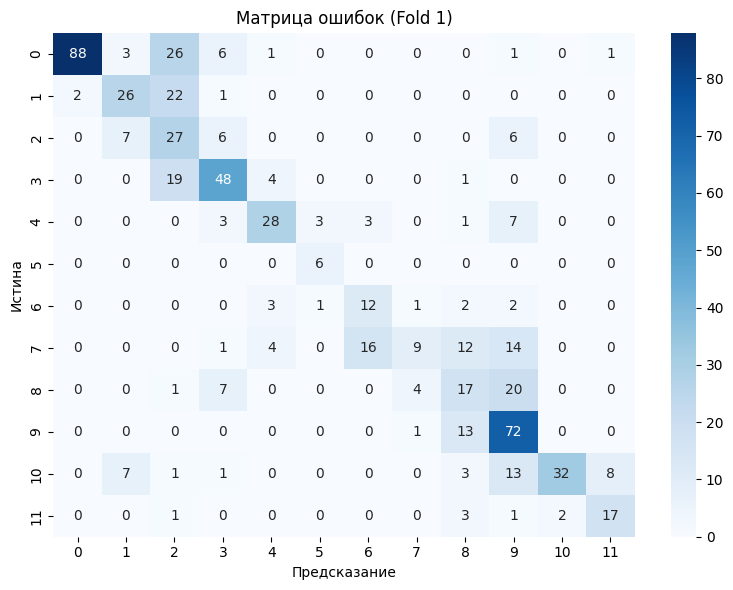

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9835
F1 macro (val):   0.6391
Gap (train-val):  0.3444

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9583    0.8214    0.8846       112
           1     0.3158    0.8571    0.4615        14
           2     0.5833    0.4565    0.5122        46
           3     0.8228    0.8442    0.8333        77
           4     0.6512    0.8235    0.7273        68
           5     0.5926    0.3556    0.4444        45
           6     0.2273    0.1852    0.2041        27
           7     0.3590    0.4516    0.4000        31
           8     0.6237    0.6824    0.6517        85
           9     0.8095    0.7658    0.7870       111
          10     1.0000    0.6818    0.8108        22
          11     0.9091    1.0000    0.9524        20

    accuracy                    

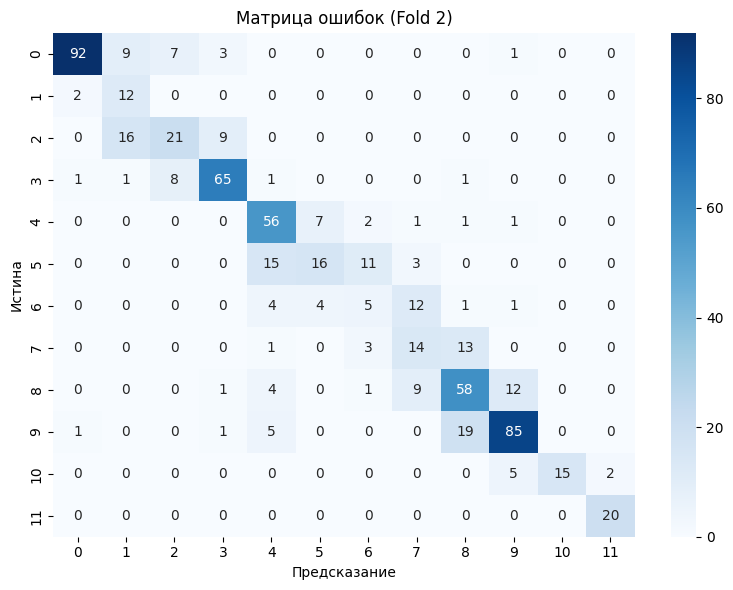

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9767
F1 macro (val):   0.6381
Gap (train-val):  0.3386

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9535    0.9840    0.9685       125
           1     0.8696    0.5556    0.6780        36
           2     0.6000    0.5625    0.5806        32
           3     0.6471    0.7333    0.6875        30
           4     0.5366    0.6111    0.5714        36
           5     0.3913    0.2500    0.3051        36
           6     0.3158    0.1818    0.2308        33
           7     0.4667    0.3500    0.4000        40
           8     0.6460    0.8295    0.7264        88
           9     0.7727    0.8718    0.8193        78
          10     0.8333    0.8889    0.8602        45
          11     0.8095    0.8500    0.8293        20

    accuracy                    

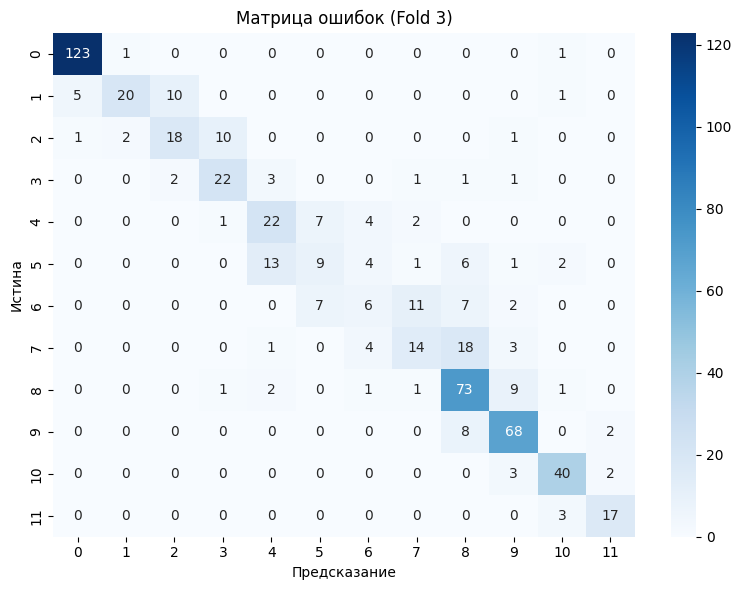

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9843
F1 macro (val):   0.5737
Gap (train-val):  0.4106

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.8769    0.9828    0.9268        58
           1     0.8125    0.3333    0.4727        39
           2     0.3582    0.6857    0.4706        35
           3     0.7907    0.6538    0.7158        52
           4     0.7391    0.6071    0.6667        56
           5     0.3571    0.4167    0.3846        24
           6     0.2500    0.2500    0.2500        28
           7     0.4444    0.0909    0.1509        44
           8     0.4688    0.4762    0.4724        63
           9     0.6389    0.9452    0.7624        73
          10     0.7879    0.9286    0.8525        56
          11     0.9565    0.6286    0.7586        35

    accuracy                    

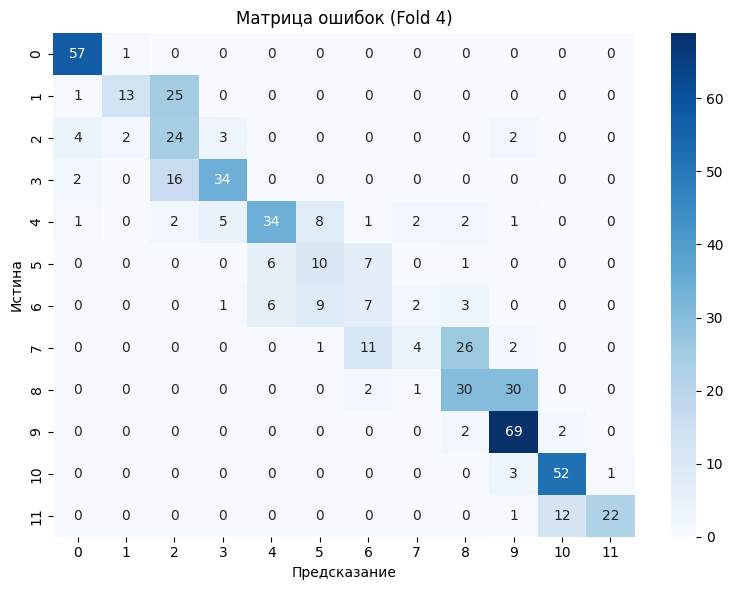

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9779
F1 macro (val):   0.5188
Gap (train-val):  0.4590

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.5909    0.9630    0.7324        27
           1     0.8000    0.2500    0.3810        16
           2     0.5185    0.6087    0.5600        23
           3     0.7619    0.8889    0.8205        36
           4     0.4444    0.7143    0.5479        28
           5     0.1667    0.1364    0.1500        22
           6     0.5000    0.4091    0.4500        22
           7     0.1724    0.2174    0.1923        23
           8     0.4752    0.6000    0.5304        80
           9     0.6571    0.5702    0.6106       121
          10     0.6341    0.6582    0.6460        79
          11     0.8667    0.4643    0.6047        84

    accuracy                    

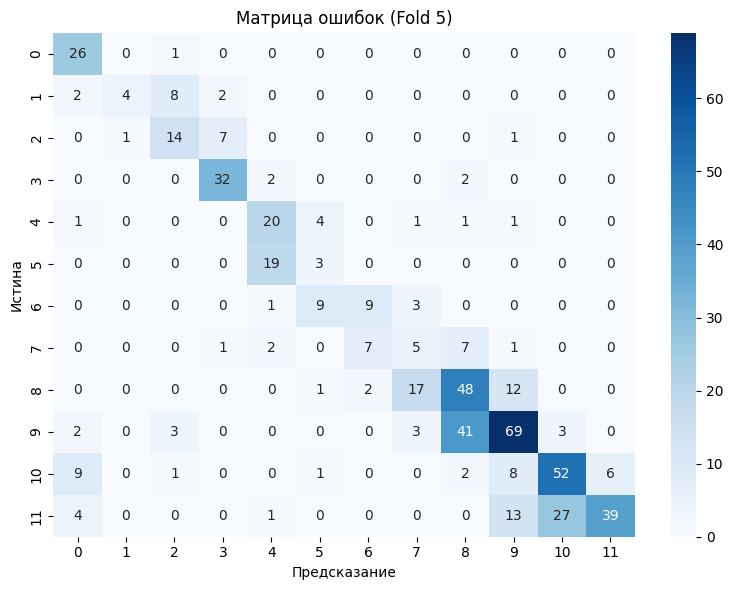

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5703
  Fold 2: F1_macro = 0.6391
  Fold 3: F1_macro = 0.6381
  Fold 4: F1_macro = 0.5737
  Fold 5: F1_macro = 0.5188

  Средний F1 macro: 0.5880 ± 0.0457

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9104    0.8616    0.8853       448
           1     0.6000    0.4808    0.5338       156
           2     0.4047    0.5714    0.4738       182
           3     0.7417    0.7528    0.7472       267
           4     0.6202    0.6867    0.6517       233
           5     0.4151    0.3308    0.3682       133
           6     0.3305    0.2977    0.3133       131
           7     0.3770    0.2371    0.2911       194
           8     0.5343    0.6192    0.5736       365
           9     0.6697    0.7740    0.7181       469
          10     0.7796    0.7154    0.7461       267
          11     0.8394    0.6284    0.7188       183

    accuracy                         0.6440      

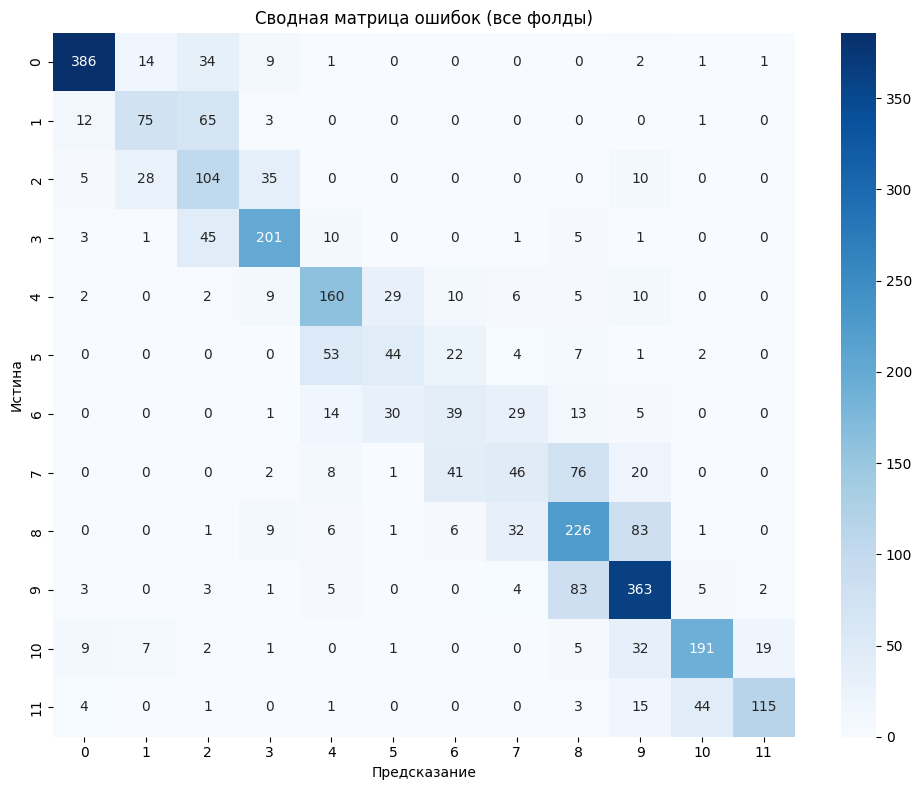

/tmp/ipykernel_397876/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

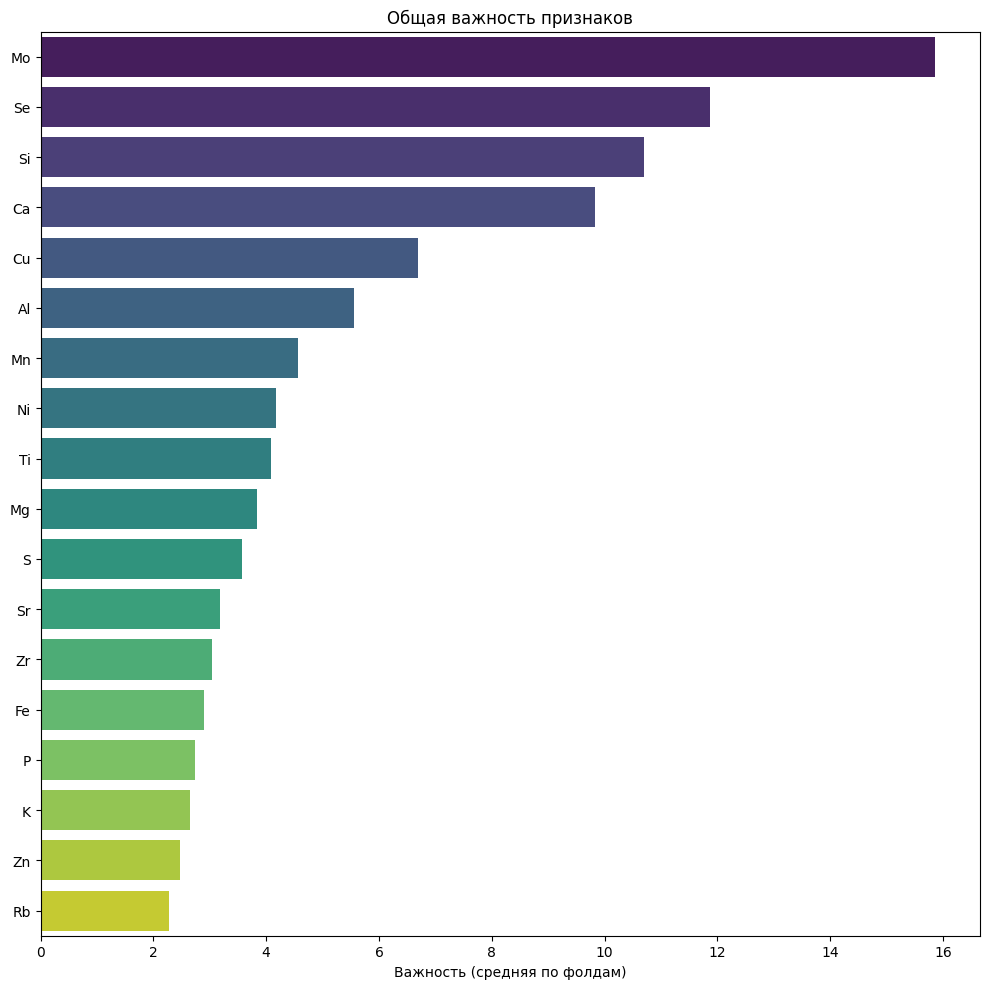

In [8]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по соотношениям элементов на новом датасете 05.10 с новой разметкой**

**31 соотношение**

In [9]:
ratios = [
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]


Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9918
F1 macro (val):   0.4836
Gap (train-val):  0.5083

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9733    0.5794    0.7264       126
           1     0.5517    0.3137    0.4000        51
           2     0.2973    0.4783    0.3667        46
           3     0.6622    0.6806    0.6712        72
           4     0.6957    0.7111    0.7033        45
           5     0.1667    0.6667    0.2667         6
           6     0.3548    0.5238    0.4231        21
           7     0.3448    0.1786    0.2353        56
           8     0.2602    0.6531    0.3721        49
           9     0.6129    0.6628    0.6369        86
          10     0.8286    0.4462    0.5800        65
          11     0.5714    0.3333    0.4211        24

    accuracy                    

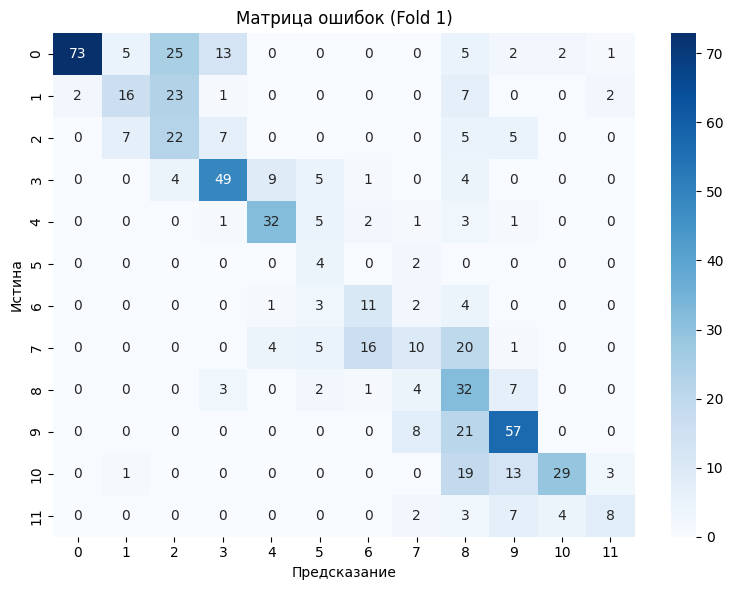

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9907
F1 macro (val):   0.6443
Gap (train-val):  0.3464

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9592    0.8393    0.8952       112
           1     0.3056    0.7857    0.4400        14
           2     0.5435    0.5435    0.5435        46
           3     0.9062    0.7532    0.8227        77
           4     0.6383    0.8824    0.7407        68
           5     0.5238    0.2444    0.3333        45
           6     0.3077    0.2963    0.3019        27
           7     0.4634    0.6129    0.5278        31
           8     0.6889    0.7294    0.7086        85
           9     0.8350    0.7748    0.8037       111
          10     0.8125    0.5909    0.6842        22
          11     0.8696    1.0000    0.9302        20

    accuracy                    

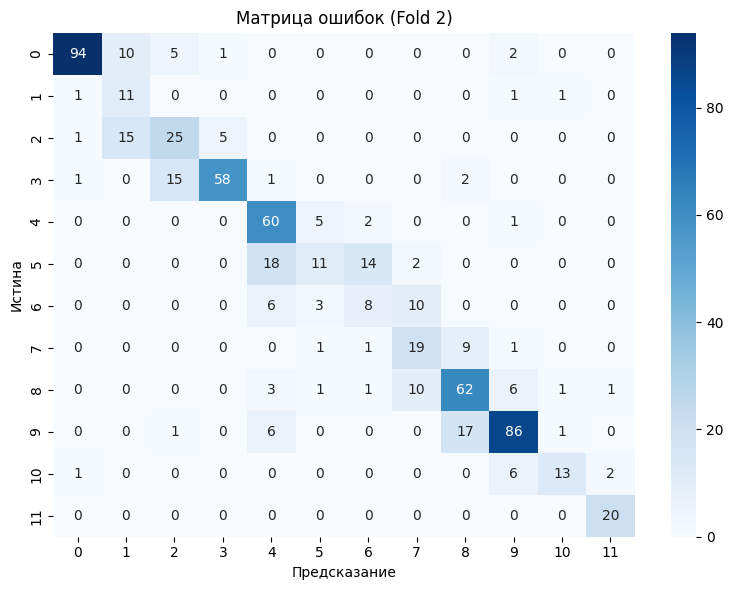

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9910
F1 macro (val):   0.6076
Gap (train-val):  0.3834

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9397    0.8720    0.9046       125
           1     0.8077    0.5833    0.6774        36
           2     0.6538    0.5312    0.5862        32
           3     0.7353    0.8333    0.7812        30
           4     0.5897    0.6389    0.6133        36
           5     0.3333    0.1111    0.1667        36
           6     0.2778    0.1515    0.1961        33
           7     0.4800    0.3000    0.3692        40
           8     0.5620    0.7727    0.6507        88
           9     0.6842    0.8333    0.7514        78
          10     0.6500    0.8667    0.7429        45
          11     0.7407    1.0000    0.8511        20

    accuracy                    

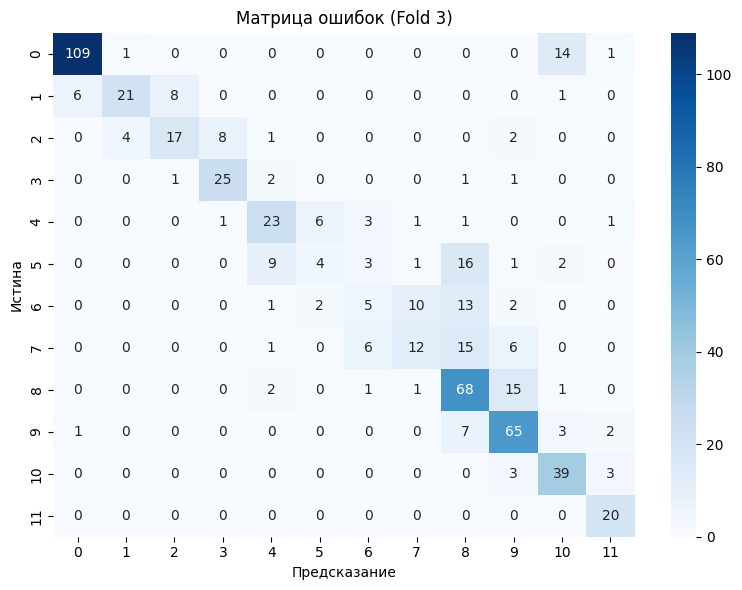

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9914
F1 macro (val):   0.5861
Gap (train-val):  0.4052

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9032    0.9655    0.9333        58
           1     0.8500    0.4359    0.5763        39
           2     0.4364    0.6857    0.5333        35
           3     0.7059    0.6923    0.6990        52
           4     0.7674    0.5893    0.6667        56
           5     0.3043    0.2917    0.2979        24
           6     0.3636    0.4286    0.3934        28
           7     0.5000    0.1591    0.2414        44
           8     0.4407    0.4127    0.4262        63
           9     0.5849    0.8493    0.6927        73
          10     0.7324    0.9286    0.8189        56
          11     0.8846    0.6571    0.7541        35

    accuracy                    

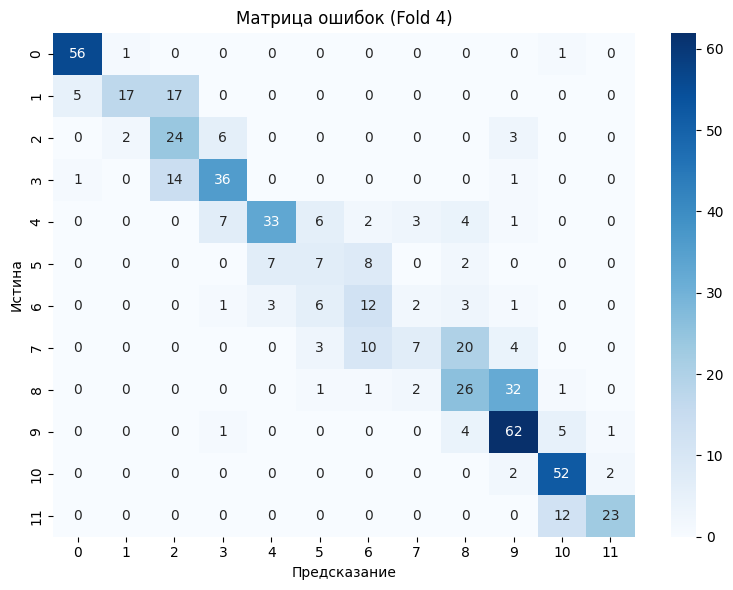

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9884
F1 macro (val):   0.5151
Gap (train-val):  0.4733

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.4333    0.9630    0.5977        27
           1     0.7778    0.4375    0.5600        16
           2     0.4828    0.6087    0.5385        23
           3     0.8378    0.8611    0.8493        36
           4     0.4902    0.8929    0.6329        28
           5     0.1579    0.1364    0.1463        22
           6     0.6000    0.4091    0.4865        22
           7     0.2432    0.3913    0.3000        23
           8     0.5526    0.5250    0.5385        80
           9     0.6094    0.6446    0.6265       121
          10     0.5714    0.5063    0.5369        79
          11     0.7000    0.2500    0.3684        84

    accuracy                    

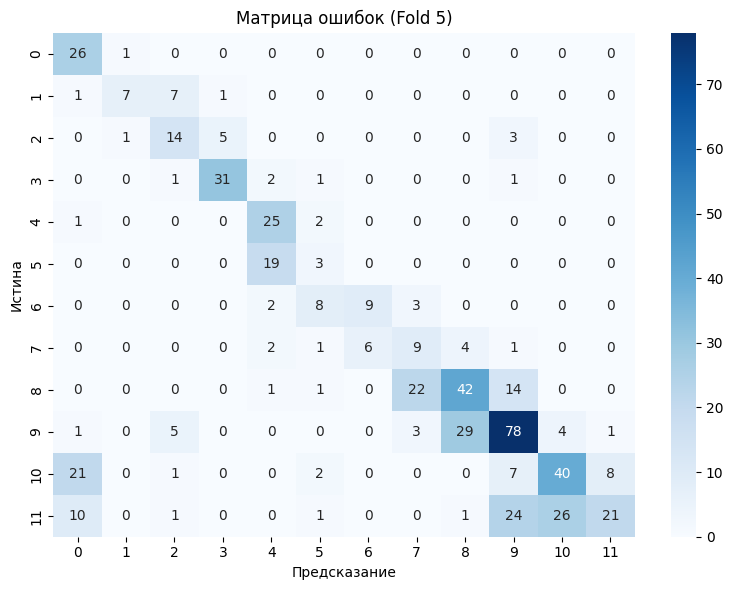

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4836
  Fold 2: F1_macro = 0.6443
  Fold 3: F1_macro = 0.6076
  Fold 4: F1_macro = 0.5861
  Fold 5: F1_macro = 0.5151

  Средний F1 macro: 0.5673 ± 0.0594

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.8710    0.7991    0.8335       448
           1     0.6000    0.4615    0.5217       156
           2     0.4435    0.5604    0.4951       182
           3     0.7654    0.7453    0.7552       267
           4     0.6337    0.7425    0.6838       233
           5     0.2929    0.2180    0.2500       133
           6     0.3659    0.3435    0.3543       131
           7     0.3904    0.2938    0.3353       194
           8     0.4904    0.6301    0.5516       365
           9     0.6629    0.7420    0.7002       469
          10     0.6865    0.6479    0.6667       267
          11     0.7667    0.5027    0.6073       183

    accuracy                         0.6202      

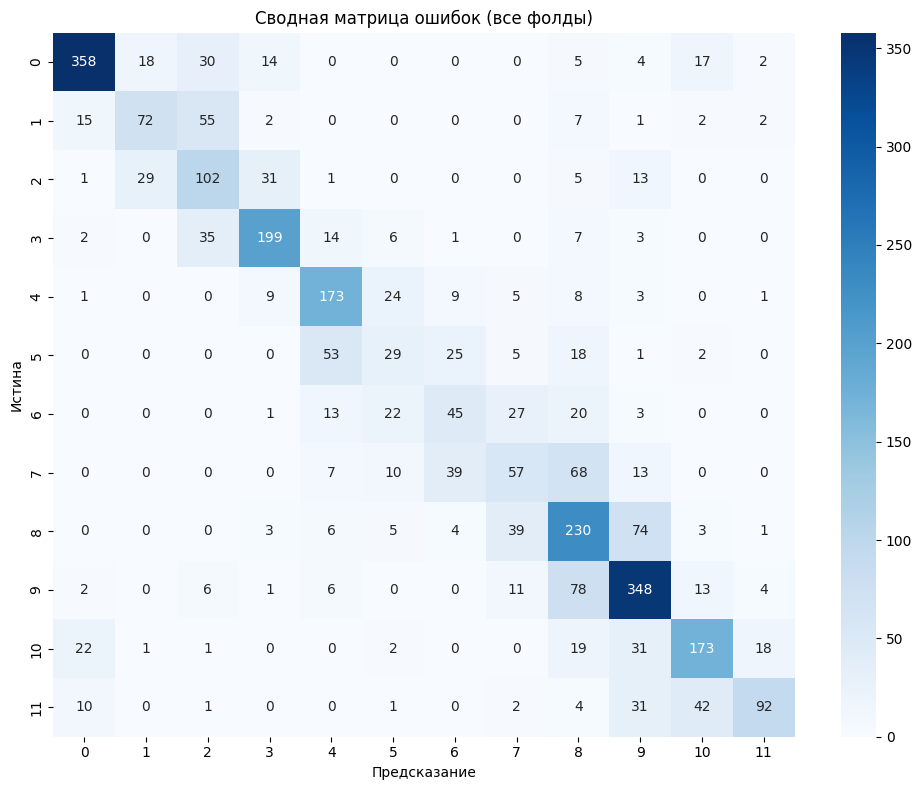

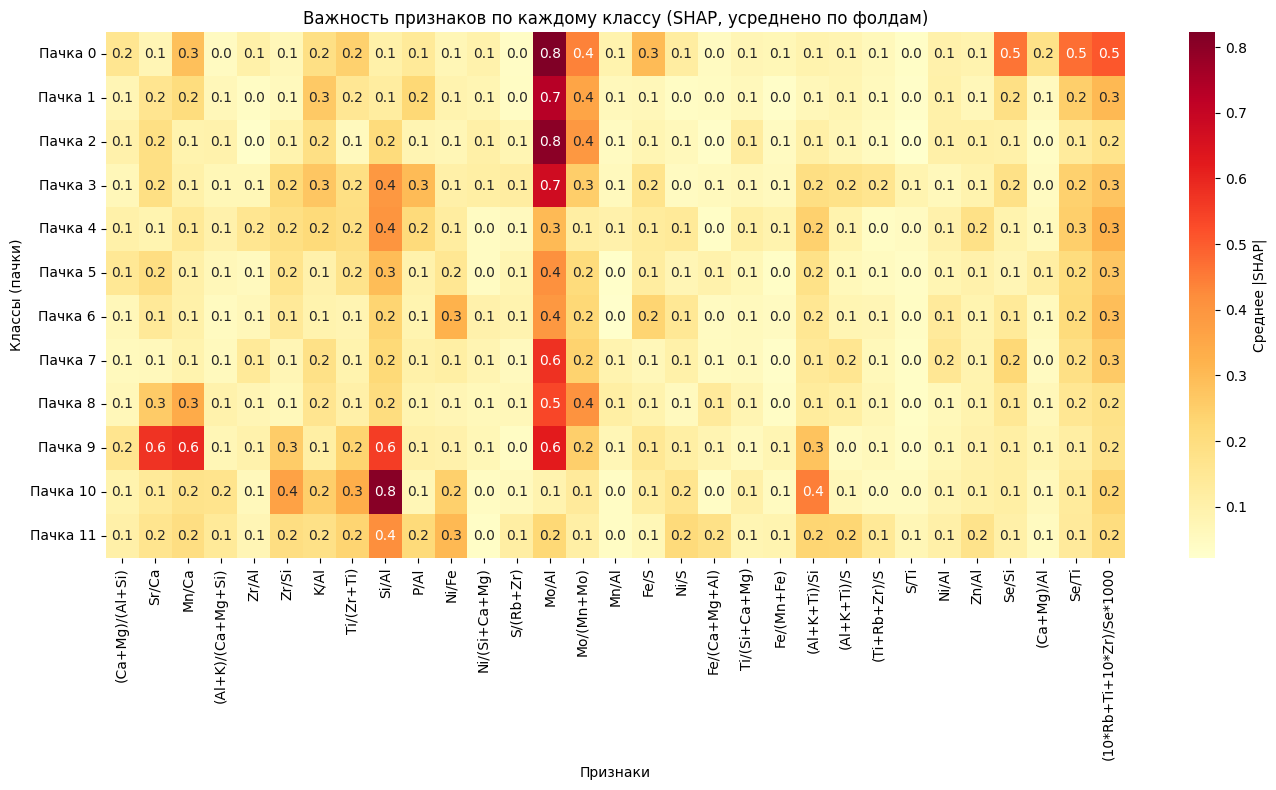

Пачка 0:
  Mo/Al: 0.823
  (10*Rb+Ti+10*Zr)/Se*1000: 0.507
  Se/Ti: 0.470
  Se/Si: 0.463
  Mo/(Mn+Mo): 0.440
  Fe/S: 0.300
  Mn/Ca: 0.285
  Ti/(Zr+Ti): 0.244
  K/Al: 0.185
  (Ca+Mg)/Al: 0.179
  (Ca+Mg)/(Al+Si): 0.159
  P/Al: 0.140
  Ni/S: 0.122
  Zr/Al: 0.103
  Si/Al: 0.102
  Ni/Al: 0.101

Пачка 1:
  Mo/Al: 0.730
  Mo/(Mn+Mo): 0.358
  (10*Rb+Ti+10*Zr)/Se*1000: 0.304
  K/Al: 0.264
  Se/Ti: 0.248
  P/Al: 0.225
  Mn/Ca: 0.206
  Se/Si: 0.185
  Sr/Ca: 0.161
  Ti/(Zr+Ti): 0.152
  Si/Al: 0.125
  Ni/Al: 0.103

Пачка 2:
  Mo/Al: 0.802
  Mo/(Mn+Mo): 0.394
  Si/Al: 0.207
  Sr/Ca: 0.189
  K/Al: 0.187
  (10*Rb+Ti+10*Zr)/Se*1000: 0.171
  Se/Ti: 0.132
  Ti/(Si+Ca+Mg): 0.128
  Ni/(Si+Ca+Mg): 0.110
  (Al+K+Ti)/Si: 0.109
  Zn/Al: 0.109
  Ni/Al: 0.104
  Se/Si: 0.103

Пачка 3:
  Mo/Al: 0.676
  Si/Al: 0.392
  P/Al: 0.298
  (10*Rb+Ti+10*Zr)/Se*1000: 0.275
  K/Al: 0.271
  Mo/(Mn+Mo): 0.251
  Se/Ti: 0.243
  Zr/Si: 0.214
  (Al+K+Ti)/Si: 0.192
  Sr/Ca: 0.191
  Ti/(Zr+Ti): 0.190
  Se/Si: 0.184
  (Al+K+Ti)/S: 0.18

/tmp/ipykernel_397876/2862472598.py:162: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

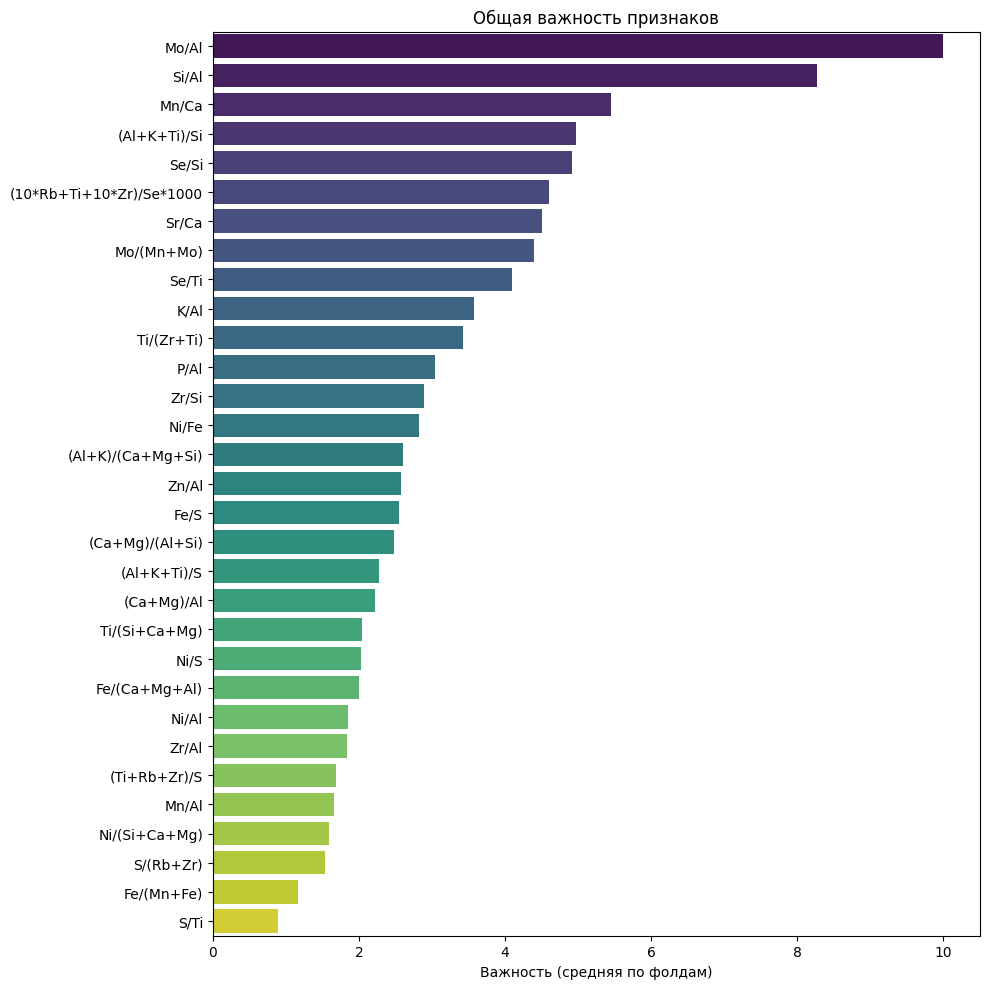

In [12]:
X = df[ratios]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# SHAP: важность по классам (усреднённая по всем фолдам)
# Объединяем SHAP всех фолдов
shap_concat = np.concatenate(shap_all, axis=0)  # (total_samples, n_classes, n_features)
mean_shap = np.abs(shap_concat).mean(axis=0)     # (n_classes, n_features)

plt.figure(figsize=(14, 8))
sns.heatmap(
    mean_shap,
    annot=True, fmt='.1f',
    cmap='YlOrRd',
    xticklabels=ratios,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Среднее |SHAP|'}
)
plt.xlabel('Признаки')
plt.ylabel('Классы (пачки)')
plt.title('Важность признаков по каждому классу (SHAP, усреднено по фолдам)')
plt.tight_layout()
plt.show()

# Топ-признаки для каждого класса
for i in range(mean_shap.shape[0]):
    significant = [(ratios[j], mean_shap[i, j])
                   for j in range(len(ratios))
                   if mean_shap[i, j] > 0.1]
    significant.sort(key=lambda x: -x[1])
    print(f"Пачка {i}:")
    for feat, v in significant:
        print(f"  {feat}: {v:.3f}")
    print()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(ratios, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по элементам и соотношениям элементов**

In [13]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9904
F1 macro (val):   0.5010
Gap (train-val):  0.4894

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9551    0.6746    0.7907       126
           1     0.6000    0.2941    0.3947        51
           2     0.3000    0.5870    0.3971        46
           3     0.5833    0.6806    0.6282        72
           4     0.6977    0.6667    0.6818        45
           5     0.2353    0.6667    0.3478         6
           6     0.3529    0.5714    0.4364        21
           7     0.4375    0.1250    0.1944        56
           8     0.2661    0.5918    0.3671        49
           9     0.6556    0.6860    0.6705        86
          10     0.8929    0.3846    0.5376        65
          11     0.5909    0.5417    0.5652        24

    accuracy                    

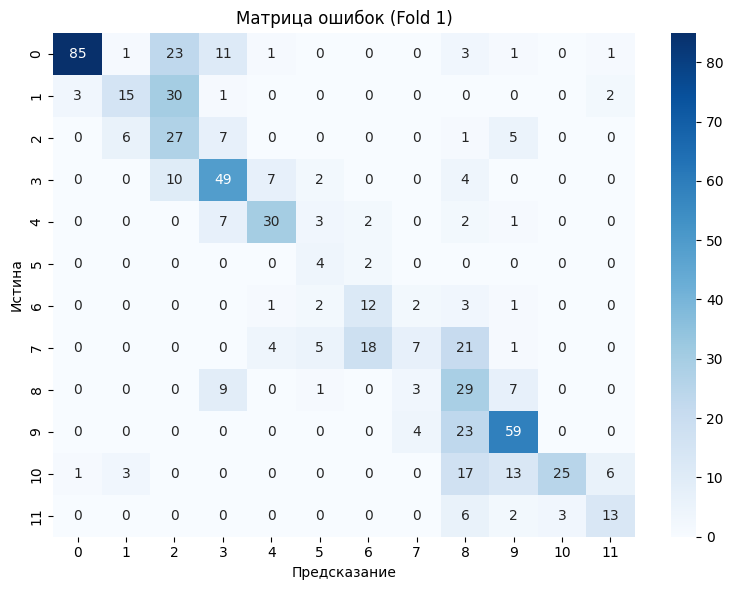

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9932
F1 macro (val):   0.6345
Gap (train-val):  0.3588

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9495    0.8393    0.8910       112
           1     0.2821    0.7857    0.4151        14
           2     0.5122    0.4565    0.4828        46
           3     0.8806    0.7662    0.8194        77
           4     0.6848    0.9265    0.7875        68
           5     0.6316    0.2667    0.3750        45
           6     0.2000    0.1852    0.1923        27
           7     0.4186    0.5806    0.4865        31
           8     0.6702    0.7412    0.7039        85
           9     0.8431    0.7748    0.8075       111
          10     0.9286    0.5909    0.7222        22
          11     0.8696    1.0000    0.9302        20

    accuracy                    

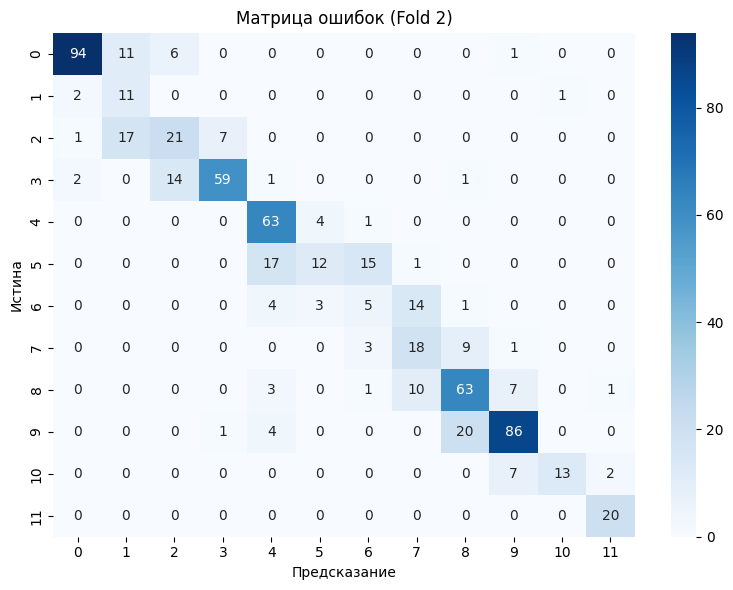

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9892
F1 macro (val):   0.6257
Gap (train-val):  0.3635

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9504    0.9200    0.9350       125
           1     0.8077    0.5833    0.6774        36
           2     0.6429    0.5625    0.6000        32
           3     0.7273    0.8000    0.7619        30
           4     0.6098    0.6944    0.6494        36
           5     0.3333    0.1667    0.2222        36
           6     0.2500    0.1212    0.1633        33
           7     0.4231    0.2750    0.3333        40
           8     0.6000    0.8182    0.6923        88
           9     0.7391    0.8718    0.8000        78
          10     0.7500    0.8667    0.8041        45
          11     0.7692    1.0000    0.8696        20

    accuracy                    

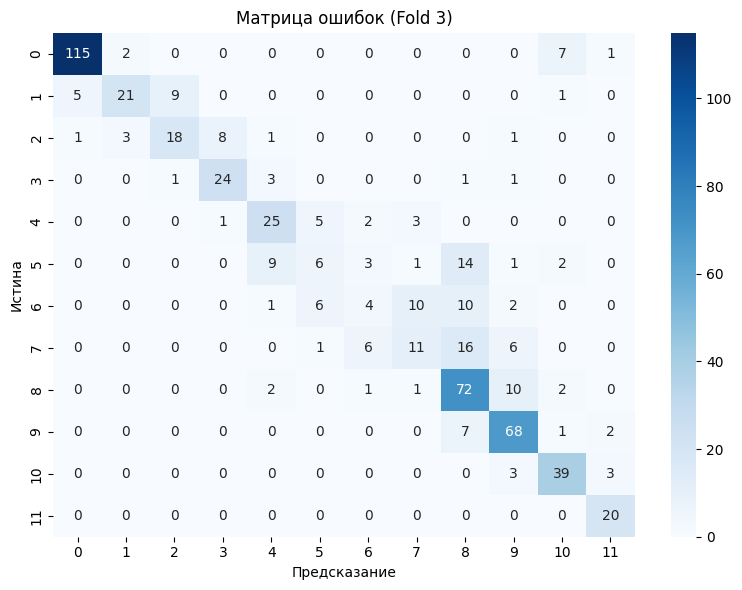

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9938
F1 macro (val):   0.5933
Gap (train-val):  0.4005

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9180    0.9655    0.9412        58
           1     0.8125    0.3333    0.4727        39
           2     0.4062    0.7429    0.5253        35
           3     0.7292    0.6731    0.7000        52
           4     0.7907    0.6071    0.6869        56
           5     0.3913    0.3750    0.3830        24
           6     0.3750    0.4286    0.4000        28
           7     0.5000    0.1818    0.2667        44
           8     0.4921    0.4921    0.4921        63
           9     0.6038    0.8767    0.7151        73
          10     0.7424    0.8750    0.8033        56
          11     0.8800    0.6286    0.7333        35

    accuracy                    

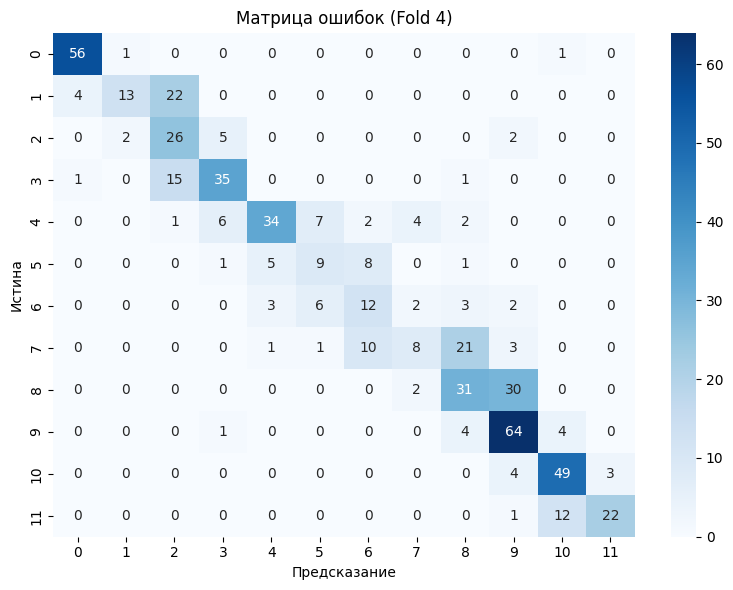

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9900
F1 macro (val):   0.5527
Gap (train-val):  0.4373

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.5909    0.9630    0.7324        27
           1     0.8333    0.3125    0.4545        16
           2     0.4333    0.5652    0.4906        23
           3     0.8158    0.8611    0.8378        36
           4     0.5319    0.8929    0.6667        28
           5     0.2273    0.2273    0.2273        22
           6     0.5000    0.4091    0.4500        22
           7     0.2424    0.3478    0.2857        23
           8     0.6000    0.5250    0.5600        80
           9     0.6538    0.7025    0.6773       121
          10     0.6543    0.6709    0.6625        79
          11     0.8810    0.4405    0.5873        84

    accuracy                    

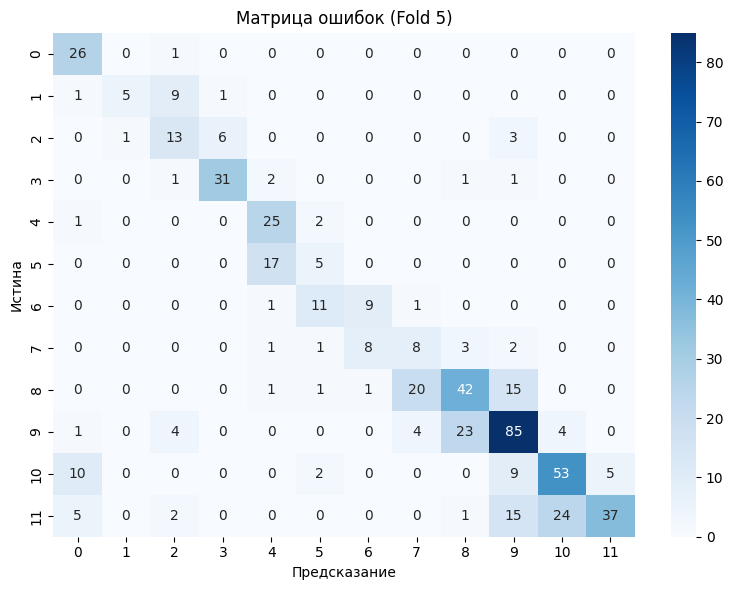

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5010
  Fold 2: F1_macro = 0.6345
  Fold 3: F1_macro = 0.6257
  Fold 4: F1_macro = 0.5933
  Fold 5: F1_macro = 0.5527

  Средний F1 macro: 0.5814 ± 0.0494

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9082    0.8393    0.8724       448
           1     0.5804    0.4167    0.4851       156
           2     0.4150    0.5769    0.4828       182
           3     0.7333    0.7416    0.7374       267
           4     0.6654    0.7597    0.7094       233
           5     0.3636    0.2707    0.3103       133
           6     0.3360    0.3206    0.3281       131
           7     0.3881    0.2680    0.3171       194
           8     0.5197    0.6493    0.5773       365
           9     0.6962    0.7719    0.7321       469
          10     0.7427    0.6704    0.7047       267
          11     0.8116    0.6120    0.6978       183

    accuracy                         0.6410      

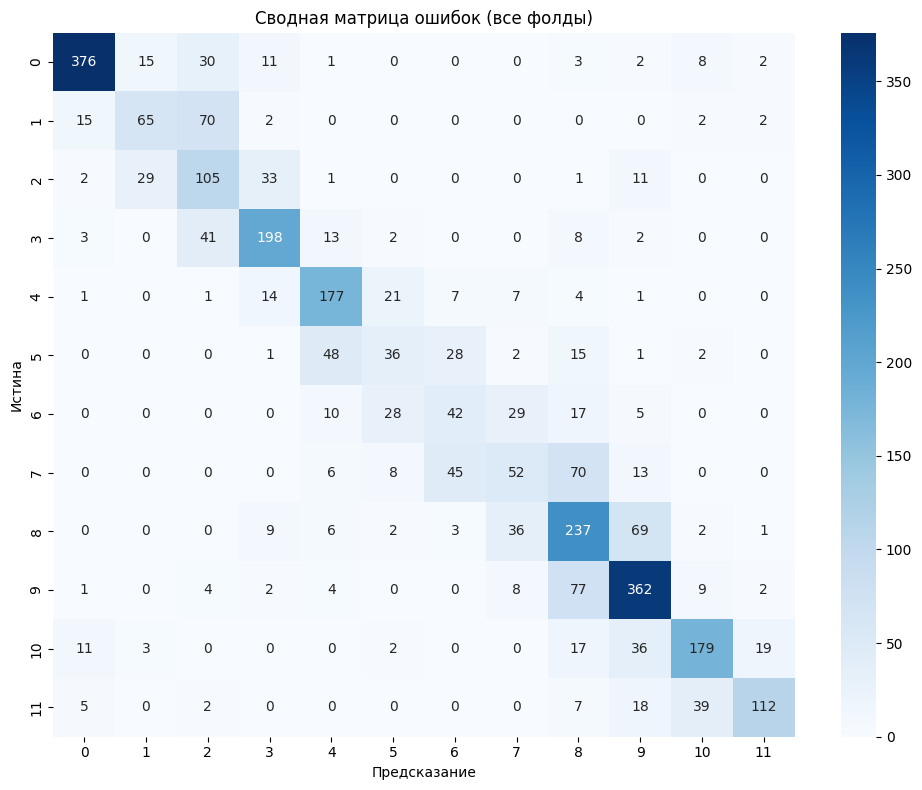

/tmp/ipykernel_397876/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

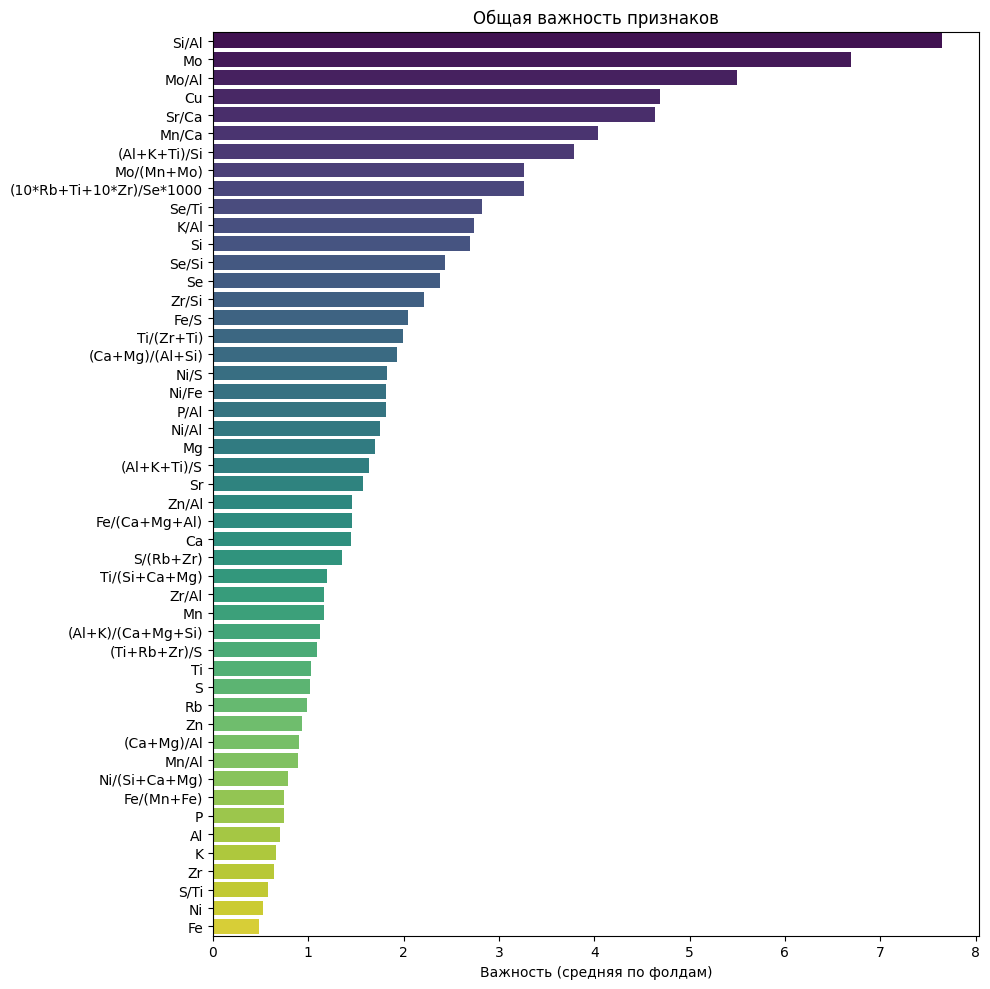

In [14]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

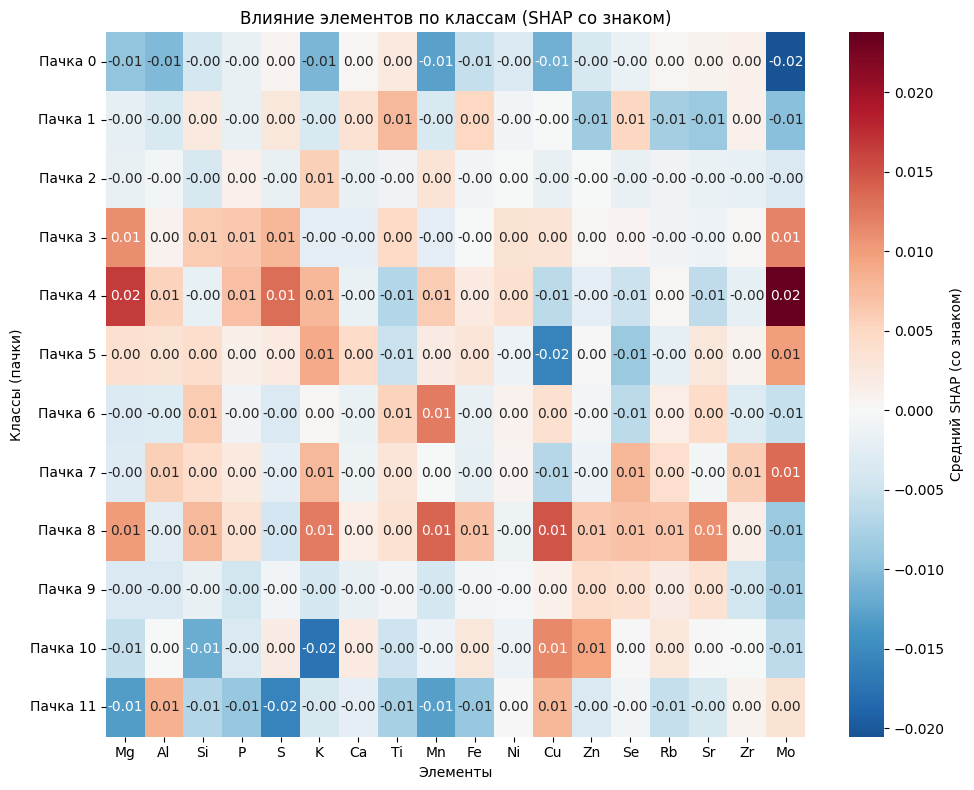

Пачка 0:
  ↓ Mo: -0.021
  ↓ Mn: -0.013
  ↓ Cu: -0.011
  ↓ K: -0.011
  ↓ Al: -0.010

Пачка 1:

Пачка 2:

Пачка 3:
  ↑ Mo: +0.012
  ↑ Mg: +0.011

Пачка 4:
  ↑ Mo: +0.024
  ↑ Mg: +0.017
  ↑ S: +0.013

Пачка 5:
  ↓ Cu: -0.016

Пачка 6:
  ↑ Mn: +0.012

Пачка 7:
  ↑ Mo: +0.013

Пачка 8:
  ↑ Cu: +0.015
  ↑ Mn: +0.014
  ↑ K: +0.012
  ↑ Sr: +0.011
  ↑ Mg: +0.010

Пачка 9:

Пачка 10:
  ↓ K: -0.017
  ↓ Si: -0.012
  ↑ Cu: +0.011

Пачка 11:
  ↓ S: -0.016
  ↓ Mg: -0.013
  ↓ Mn: -0.013



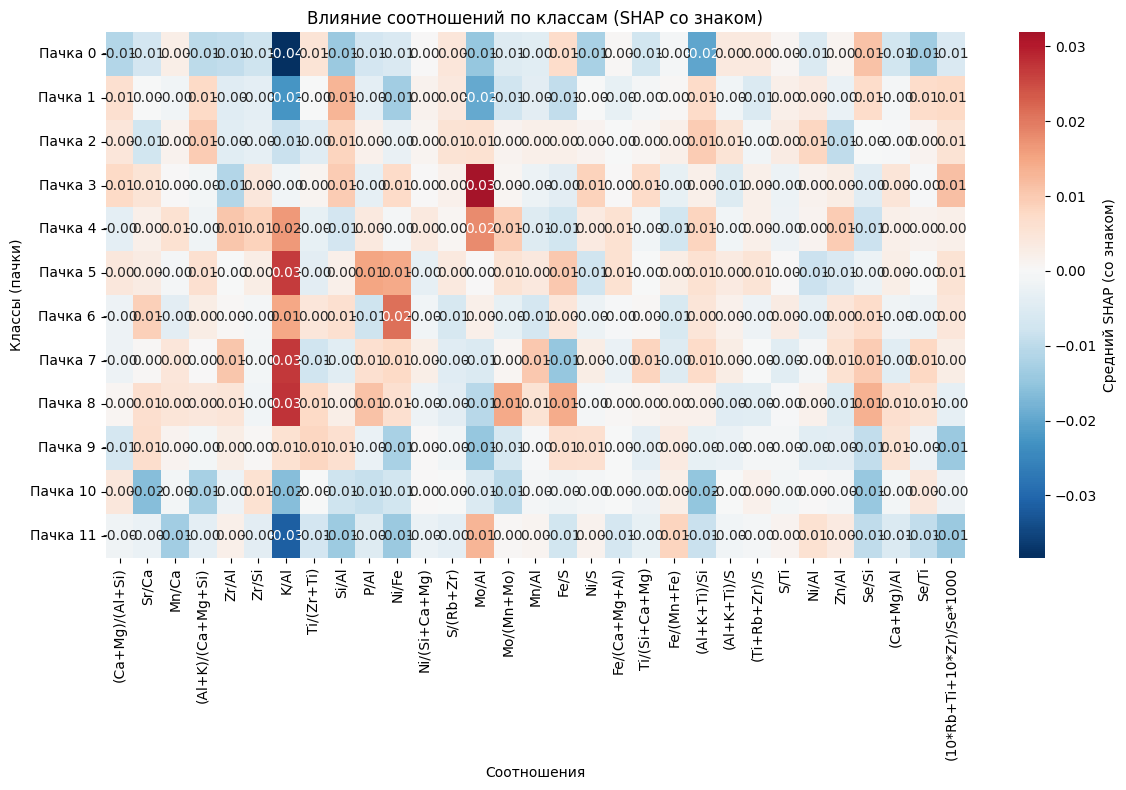

Пачка 0:
  ↓ K/Al: -0.038
  ↓ (Al+K+Ti)/Si: -0.020
  ↓ Mo/Al: -0.015
  ↓ Si/Al: -0.014
  ↓ Se/Ti: -0.013
  ↓ Ni/S: -0.012
  ↑ Se/Si: +0.011
  ↓ (Ca+Mg)/(Al+Si): -0.011

Пачка 1:
  ↓ K/Al: -0.022
  ↓ Mo/Al: -0.019
  ↓ Ni/Fe: -0.013
  ↑ Si/Al: +0.013

Пачка 2:

Пачка 3:
  ↑ Mo/Al: +0.032
  ↑ (10*Rb+Ti+10*Zr)/Se*1000: +0.011
  ↓ Zr/Al: -0.011

Пачка 4:
  ↑ Mo/Al: +0.018
  ↑ K/Al: +0.016
  ↑ Zr/Al: +0.011

Пачка 5:
  ↑ K/Al: +0.027
  ↑ P/Al: +0.015
  ↑ Ni/Fe: +0.015
  ↑ Fe/S: +0.010

Пачка 6:
  ↑ Ni/Fe: +0.021
  ↑ K/Al: +0.015

Пачка 7:
  ↑ K/Al: +0.027
  ↓ Fe/S: -0.015
  ↑ Zr/Al: +0.011
  ↑ Mn/Al: +0.010

Пачка 8:
  ↑ K/Al: +0.028
  ↑ Mo/(Mn+Mo): +0.014
  ↑ Fe/S: +0.014
  ↑ Se/Si: +0.014
  ↑ P/Al: +0.011
  ↓ Mo/Al: -0.011

Пачка 9:
  ↓ Mo/Al: -0.015
  ↓ (10*Rb+Ti+10*Zr)/Se*1000: -0.014
  ↓ Ni/Fe: -0.012

Пачка 10:
  ↓ Sr/Ca: -0.016
  ↓ K/Al: -0.016
  ↓ (Al+K+Ti)/Si: -0.015
  ↓ Se/Si: -0.014
  ↓ (Al+K)/(Ca+Mg+Si): -0.013
  ↓ Mo/(Mn+Mo): -0.010

Пачка 11:
  ↓ K/Al: -0.031
  ↓ (10*Rb+Ti+10*Z

In [15]:
# SHAP со знаком, разделённый на элементы и соотношения
shap_concat = np.concatenate(shap_all, axis=0)  
mean_shap = shap_concat.mean(axis=0)             

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

ratios = [
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

elem_idx = [features.index(e) for e in elements]
ratio_idx = [features.index(r) for r in ratios]

mean_shap_elem = mean_shap[:, elem_idx]    # (n_classes, n_elements)
mean_shap_ratio = mean_shap[:, ratio_idx]  # (n_classes, n_ratios)

# Таблица 1: Элементы
plt.figure(figsize=(10, 8))
sns.heatmap(
    mean_shap_elem,
    annot=True, fmt='.2f',
    cmap='RdBu_r',
    center=0,
    xticklabels=elements,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Средний SHAP (со знаком)'}
)
plt.xlabel('Элементы')
plt.ylabel('Классы (пачки)')
plt.title('Влияние элементов по классам (SHAP со знаком)')
plt.tight_layout()
plt.show()

# Вывод топ-элементов по пачкам
for i in range(mean_shap_elem.shape[0]):
    significant = [(elements[j], mean_shap_elem[i, j])
                   for j in range(len(elements))
                   if abs(mean_shap_elem[i, j]) > 0.01]
    significant.sort(key=lambda x: -abs(x[1]))
    print(f"Пачка {i}:")
    for feat, v in significant:
        direction = "↑" if v > 0 else "↓"
        print(f"  {direction} {feat}: {v:+.3f}")
    print()

# Таблица 2: Соотношения
plt.figure(figsize=(12, 8))
sns.heatmap(
    mean_shap_ratio,
    annot=True, fmt='.2f',
    cmap='RdBu_r',
    center=0,
    xticklabels=ratios,
    yticklabels=[f'Пачка {i}' for i in range(12)],
    cbar_kws={'label': 'Средний SHAP (со знаком)'}
)
plt.xlabel('Соотношения')
plt.ylabel('Классы (пачки)')
plt.title('Влияние соотношений по классам (SHAP со знаком)')
plt.tight_layout()
plt.show()

# Вывод топ-соотношений по пачкам
for i in range(mean_shap_ratio.shape[0]):
    significant = [(ratios[j], mean_shap_ratio[i, j])
                   for j in range(len(ratios))
                   if abs(mean_shap_ratio[i, j]) > 0.01]
    significant.sort(key=lambda x: -abs(x[1]))
    print(f"Пачка {i}:")
    for feat, v in significant:
        direction = "↑" if v > 0 else "↓"
        print(f"  {direction} {feat}: {v:+.3f}")
    print()


**Только с важными признаками**

In [8]:
features = [
    'Mo', 'Mn', 'Cu', 'K', 'Al', 'Mg', 'S', 'Sr',
    'K/Al', 'Mo/Al', 'Ni/Fe', 'Si/Al', 'Se/Si', 'Zr/Al', 'Fe/S', 'P/Al',
    '(10*Rb+Ti+10*Zr)/Se*1000', '(Al+K+Ti)/Si', 'Mo/(Mn+Mo)',
    '(Ca+Mg)/(Al+Si)', '(Al+K)/(Ca+Mg+Si)', 'Se/Ti', 'Ni/S',
    'Sr/Ca', 'Mn/Al', 'Mn/Ca'
]


Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9874
F1 macro (val):   0.4667
Gap (train-val):  0.5207

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9419    0.6429    0.7642       126
           1     0.5588    0.3725    0.4471        51
           2     0.2812    0.5870    0.3803        46
           3     0.6471    0.6111    0.6286        72
           4     0.6458    0.6889    0.6667        45
           5     0.2727    0.5000    0.3529         6
           6     0.3611    0.6190    0.4561        21
           7     0.4000    0.1429    0.2105        56
           8     0.2540    0.6531    0.3657        49
           9     0.6277    0.6860    0.6556        86
          10     1.0000    0.2462    0.3951        65
          11     0.4167    0.2083    0.2778        24

    accuracy                    

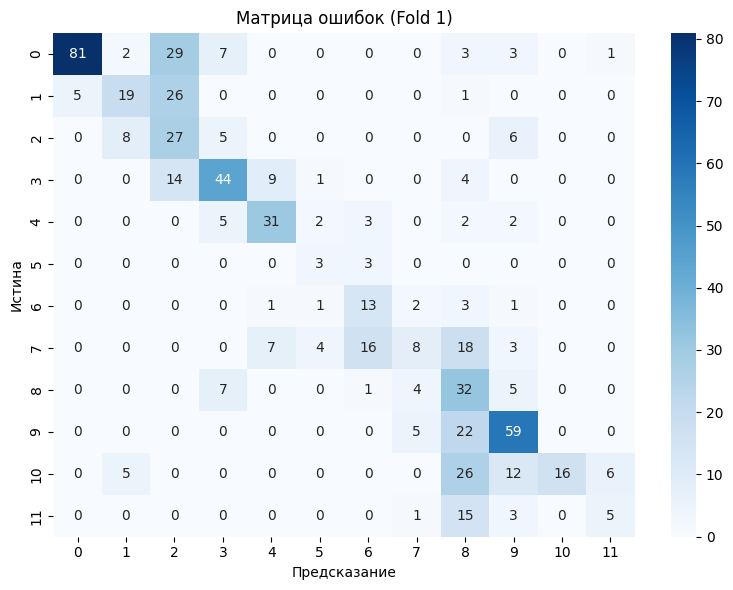

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9904
F1 macro (val):   0.6502
Gap (train-val):  0.3402

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9406    0.8482    0.8920       112
           1     0.2973    0.7857    0.4314        14
           2     0.5000    0.5217    0.5106        46
           3     0.8871    0.7143    0.7914        77
           4     0.7111    0.9412    0.8101        68
           5     0.6842    0.2889    0.4062        45
           6     0.2759    0.2963    0.2857        27
           7     0.3750    0.4839    0.4225        31
           8     0.7000    0.7412    0.7200        85
           9     0.8476    0.8018    0.8241       111
          10     1.0000    0.6364    0.7778        22
          11     0.8696    1.0000    0.9302        20

    accuracy                    

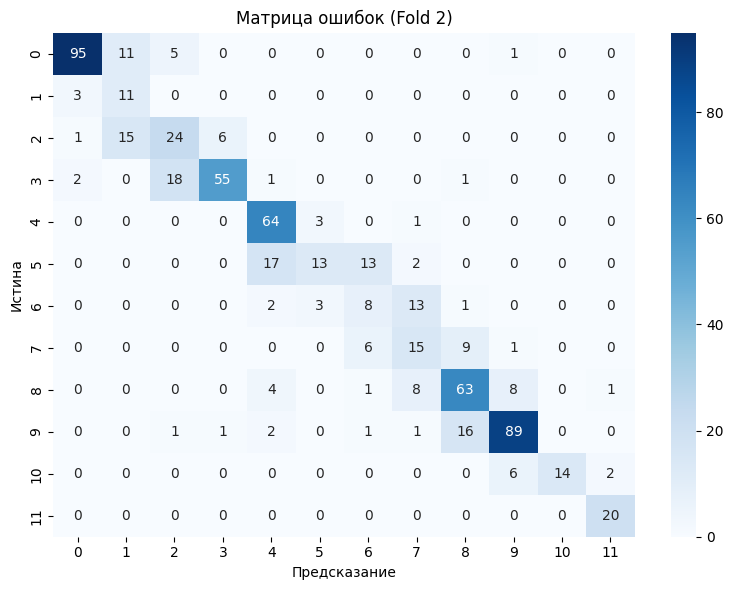

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9841
F1 macro (val):   0.6345
Gap (train-val):  0.3496

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9453    0.9680    0.9565       125
           1     0.8077    0.5833    0.6774        36
           2     0.6400    0.5000    0.5614        32
           3     0.6944    0.8333    0.7576        30
           4     0.6757    0.6944    0.6849        36
           5     0.5000    0.2222    0.3077        36
           6     0.2353    0.1212    0.1600        33
           7     0.3600    0.2250    0.2769        40
           8     0.5920    0.8409    0.6948        88
           9     0.7312    0.8718    0.7953        78
          10     0.8200    0.9111    0.8632        45
          11     0.8571    0.9000    0.8780        20

    accuracy                    

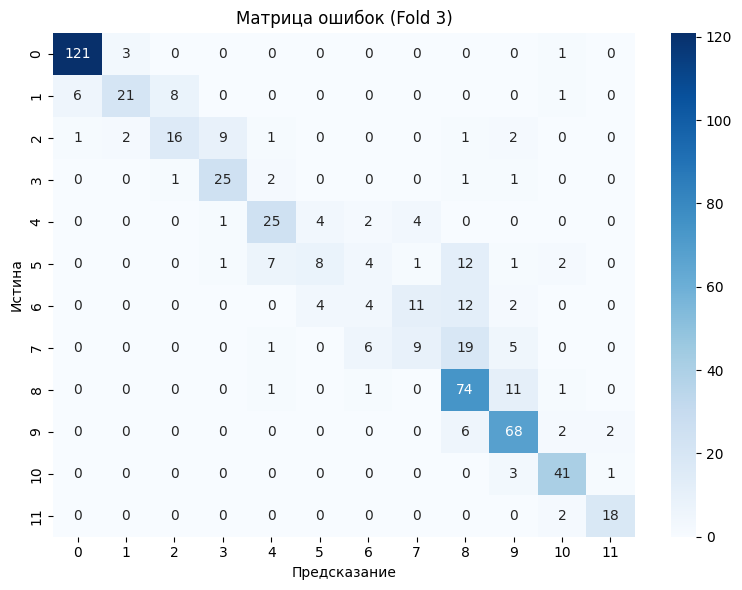

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9887
F1 macro (val):   0.6439
Gap (train-val):  0.3448

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9333    0.9655    0.9492        58
           1     0.8500    0.4359    0.5763        39
           2     0.4576    0.7714    0.5745        35
           3     0.7255    0.7115    0.7184        52
           4     0.8636    0.6786    0.7600        56
           5     0.4400    0.4583    0.4490        24
           6     0.5667    0.6071    0.5862        28
           7     0.4667    0.1591    0.2373        44
           8     0.5000    0.5238    0.5116        63
           9     0.6139    0.8493    0.7126        73
          10     0.7647    0.9286    0.8387        56
          11     1.0000    0.6857    0.8136        35

    accuracy                    

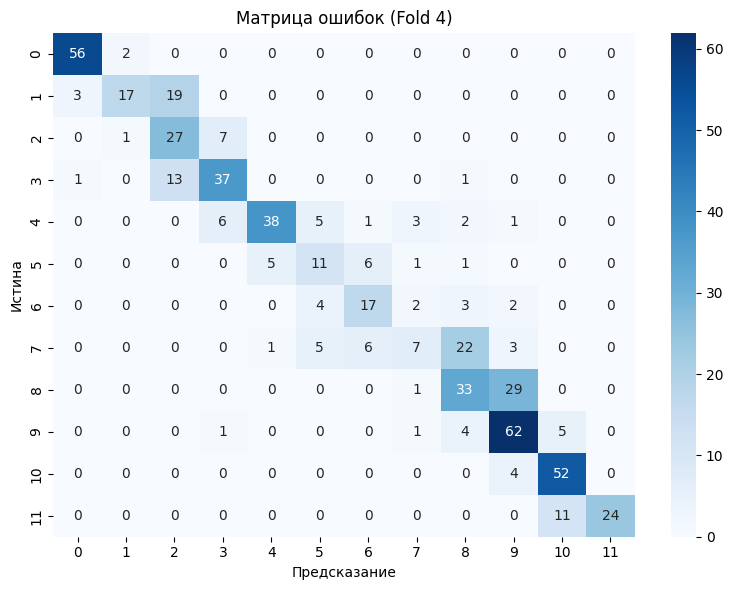

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9913
F1 macro (val):   0.5372
Gap (train-val):  0.4541

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6585    1.0000    0.7941        27
           1     1.0000    0.4375    0.6087        16
           2     0.5161    0.6957    0.5926        23
           3     0.8250    0.9167    0.8684        36
           4     0.4545    0.8929    0.6024        28
           5     0.1250    0.0909    0.1053        22
           6     0.4706    0.3636    0.4103        22
           7     0.1250    0.1739    0.1455        23
           8     0.4835    0.5500    0.5146        80
           9     0.6739    0.5124    0.5822       121
          10     0.5833    0.7089    0.6400        79
          11     0.8605    0.4405    0.5827        84

    accuracy                    

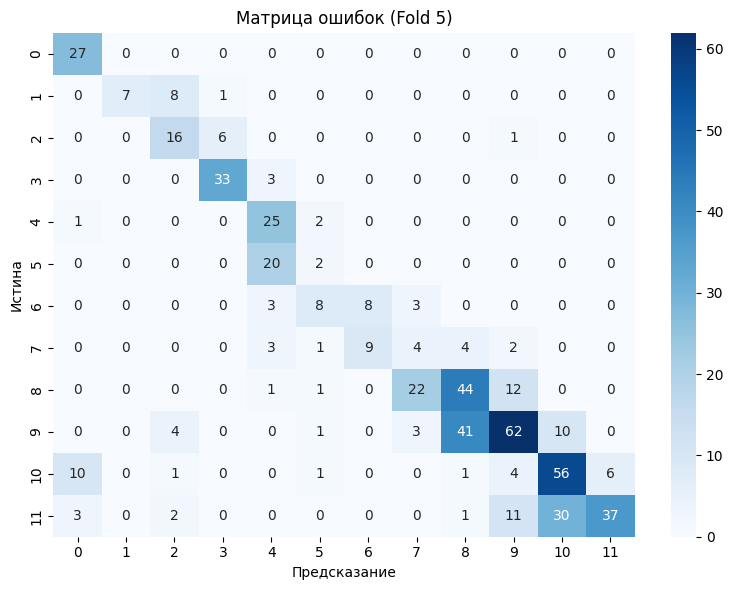

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4667
  Fold 2: F1_macro = 0.6502
  Fold 3: F1_macro = 0.6345
  Fold 4: F1_macro = 0.6439
  Fold 5: F1_macro = 0.5372

  Средний F1 macro: 0.5865 ± 0.0727

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9135    0.8482    0.8796       448
           1     0.6048    0.4808    0.5357       156
           2     0.4247    0.6044    0.4989       182
           3     0.7549    0.7266    0.7405       267
           4     0.6679    0.7854    0.7219       233
           5     0.4253    0.2782    0.3364       133
           6     0.3876    0.3817    0.3846       131
           7     0.3258    0.2216    0.2638       194
           8     0.4940    0.6740    0.5701       365
           9     0.7010    0.7249    0.7128       469
          10     0.7336    0.6704    0.7006       267
          11     0.8455    0.5683    0.6797       183

    accuracy                         0.6410      

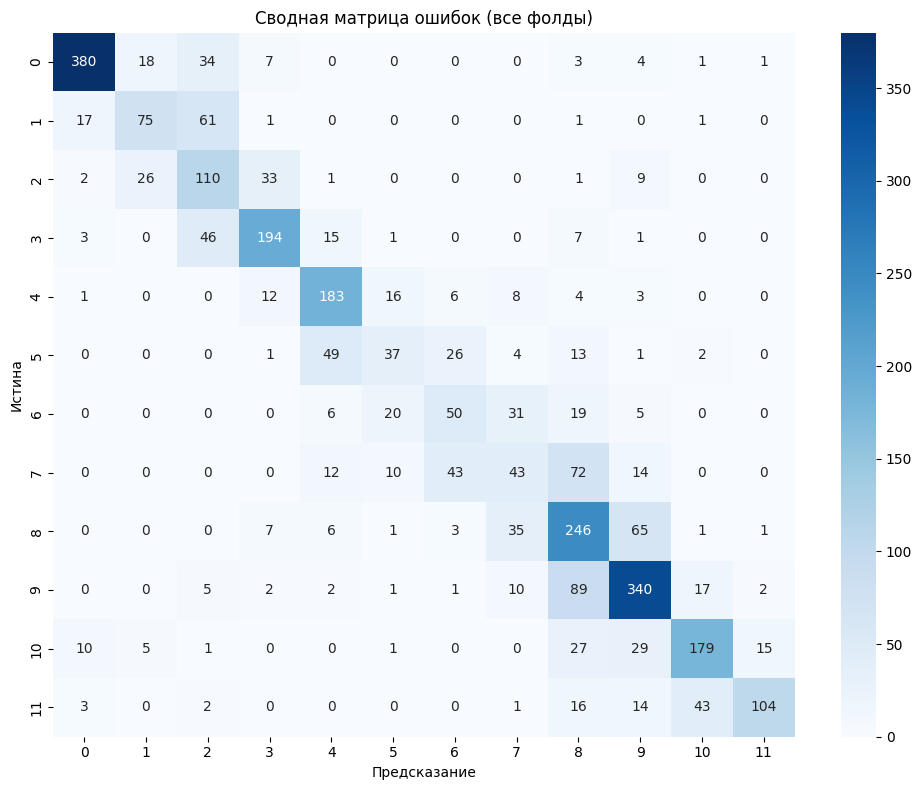

/tmp/ipykernel_402337/1167522210.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

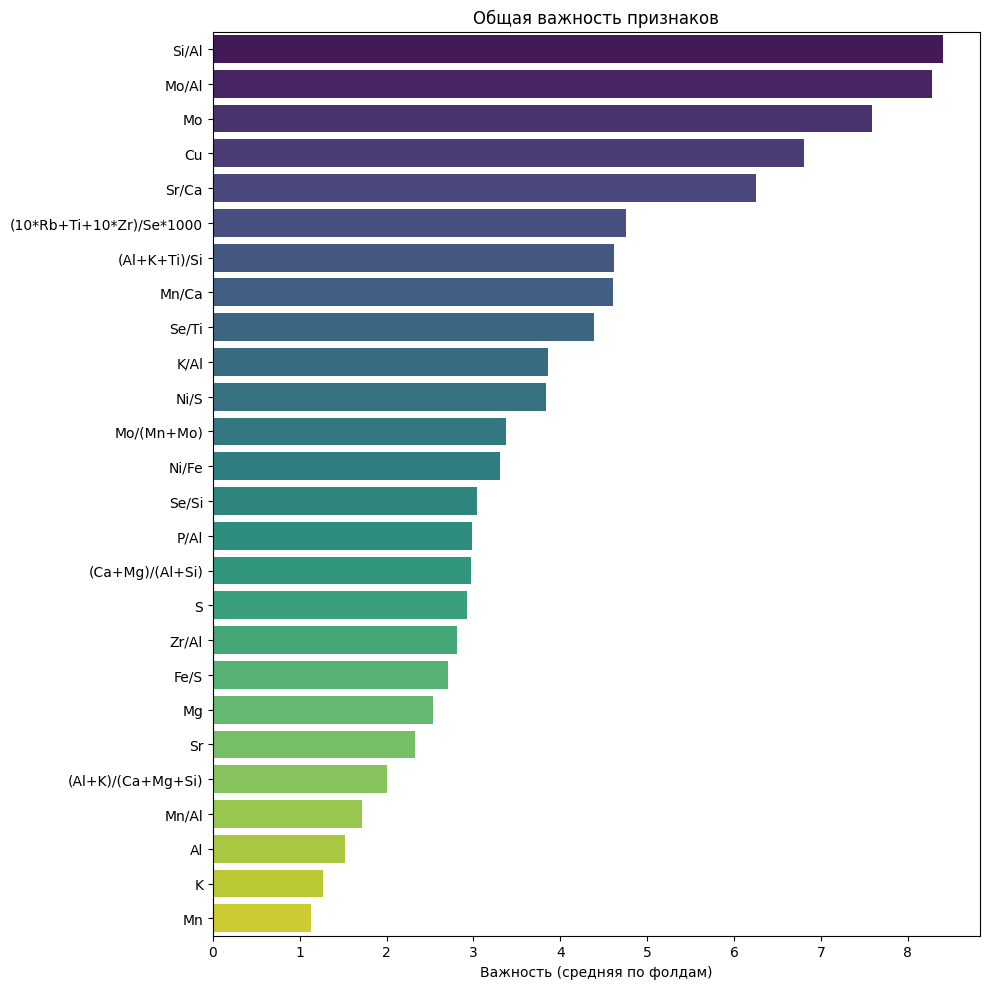

In [9]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()